In [4]:
from __future__ import annotations

import csv
import math
from collections import defaultdict
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable

import pulp as pl

In [5]:
DAYS = tuple(range(1, 8))
SLOTS_PER_DAY = 48


@dataclass(frozen=True)
class Employee:
    id: str
    service: str
    weekly_hours: float
    rest_day: int
    # "fixed": exactamente weekly_hours cuando sea alcanzable.
    # "flexible": desde weekly_hours hasta weekly_hours*(1+slack_pct).
    hours_mode: str = "fixed"
    # 0.10 equivale a una holgura del 10 %.
    slack_pct: float = 0.0


@dataclass(frozen=True)
class Shift:
    id: str
    office: str
    service: str
    start: str
    end: str
    break_start: str | None
    break_end: str | None
    # Ejemplo: (1, 2, 3, 4, 5, 6) significa lunes a sábado.
    days: tuple[int, ...]


@dataclass(frozen=True)
class HourlyPermission:
    employee_id: str
    day: int
    start: str
    end: str


def time_to_slot(value: str) -> int:
    """Convierte HH:MM a índice de media hora; admite 24:00 como fin."""
    try:
        hour_text, minute_text = value.strip().split(":")
        hour, minute = int(hour_text), int(minute_text)
    except (ValueError, AttributeError) as exc:
        raise ValueError(f"Hora inválida: {value!r}. Usa HH:MM.") from exc

    if minute not in (0, 30):
        raise ValueError(f"La hora {value!r} no está alineada a :00 o :30.")
    if hour == 24 and minute == 0:
        return SLOTS_PER_DAY
    if not (0 <= hour < 24):
        raise ValueError(f"Hora fuera de rango: {value!r}.")
    return hour * 2 + minute // 30


def slot_to_time(slot: int) -> str:
    if not (0 <= slot <= SLOTS_PER_DAY):
        raise ValueError(f"Índice de slot inválido: {slot}.")
    return f"{slot // 2:02d}:{'30' if slot % 2 else '00'}"


def hours_to_slots(hours: float, description: str) -> int:
    """Convierte horas a medias horas y exige múltiplos de 0,5 horas."""
    raw = float(hours) * 2
    rounded = round(raw)
    if abs(raw - rounded) > 1e-7:
        raise ValueError(
            f"{description}={hours} h no es múltiplo de 0,5 h. "
            "Las jornadas usan slots de 30 minutos."
        )
    if rounded < 0:
        raise ValueError(f"{description} no puede ser negativo.")
    return int(rounded)


def shift_work_slots(shift: Shift) -> frozenset[int]:
    """Slots trabajados en la jornada, excluyendo el descanso."""
    start = time_to_slot(shift.start)
    end = time_to_slot(shift.end)
    if not (0 <= start < end <= SLOTS_PER_DAY):
        raise ValueError(
            f"Jornada {shift.id}: el inicio debe ser anterior al fin y estar dentro del día."
        )

    if shift.break_start is None and shift.break_end is None:
        break_start = break_end = None
    elif shift.break_start is None or shift.break_end is None:
        raise ValueError(
            f"Jornada {shift.id}: define ambos extremos del descanso o deja ambos en None."
        )
    else:
        break_start = time_to_slot(shift.break_start)
        break_end = time_to_slot(shift.break_end)
        if not (start <= break_start <= break_end <= end):
            raise ValueError(
                f"Jornada {shift.id}: el descanso debe estar dentro de la jornada."
            )

    result = []
    for slot in range(start, end):
        in_break = (
            break_start is not None
            and break_end is not None
            and break_start <= slot < break_end
        )
        if not in_break:
            result.append(slot)
    return frozenset(result)


def permission_slots(permission: HourlyPermission) -> frozenset[int]:
    start = time_to_slot(permission.start)
    end = time_to_slot(permission.end)
    if not (0 <= start < end <= SLOTS_PER_DAY):
        raise ValueError(
            f"Permiso de {permission.employee_id}, día {permission.day}: "
            "el inicio debe ser anterior al fin."
        )
    return frozenset(range(start, end))


def _new_variable(model: pl.LpProblem, name: str, cat: str, low_bound: float = 0):
    """Compatible con PuLP 3.x y 4.x, que cambió la creación de variables."""
    if hasattr(model, "add_variable"):
        return model.add_variable(name, lowBound=low_bound, cat=cat)
    return pl.LpVariable(name, lowBound=low_bound, cat=cat)


def _normalise_demand(
    demand: dict[tuple[str, str, int, str | int], int]
) -> dict[tuple[str, str, int, int], int]:
    """Normaliza claves (oficina, servicio, día, hora o slot) a slots enteros."""
    normalised: dict[tuple[str, str, int, int], int] = {}
    for key, quantity in demand.items():
        if len(key) != 4:
            raise ValueError(
                "Cada clave de demanda debe ser (oficina, servicio, día, hora). "
                f"Recibida: {key!r}."
            )
        office, service, day, time_or_slot = key
        service_name = str(service).strip()
        if not service_name:
            raise ValueError(f"La demanda de la oficina {office!r} no tiene tipo de servicio.")
        if day not in DAYS:
            raise ValueError(f"Día inválido en demanda: {day}; usa 1..7.")
        slot = time_to_slot(time_or_slot) if isinstance(time_or_slot, str) else int(time_or_slot)
        if not (0 <= slot < SLOTS_PER_DAY):
            raise ValueError(f"Slot de demanda inválido: {time_or_slot!r}.")
        if int(quantity) != quantity or quantity < 0:
            raise ValueError(
                f"Demanda inválida en {(office, service_name, day, time_or_slot)}: {quantity}."
            )
        normalised[(str(office), service_name, int(day), slot)] = int(quantity)
    return normalised


def _reachable_weekly_totals(
    employee_id: str,
    candidates_by_day: dict[tuple[str, int], list[Shift]],
    counted_hours_slots: dict[tuple[str, str, int], frozenset[int]],
) -> set[int]:
    """Totales semanales alcanzables con cero o una jornada por día."""
    totals = {0}
    for day in DAYS:
        choices = {0}
        for shift in candidates_by_day[(employee_id, day)]:
            choices.add(len(counted_hours_slots[(employee_id, shift.id, day)]))
        totals = {previous + choice for previous in totals for choice in choices}
    return totals


def solve_schedule(
    employees: list[Employee],
    shifts: list[Shift],
    demand: dict[tuple[str, str, int, str | int], int],
    full_day_permissions: set[tuple[str, int]] | None = None,
    hourly_permissions: list[HourlyPermission] | None = None,
    *,
    shortage_weight: float = 1.0,
    overstaff_weight: float = 1.0,
    time_limit_seconds: int = 120,
    solver_log: bool = False,
    hourly_permissions_count_as_worked: bool = False,
):
    """Resuelve la planeación semanal.

    La demanda tiene claves (oficina, servicio, día, hora_inicio_slot) y
    representa el número de trabajadores de ese servicio requeridos en esa
    oficina y slot de 30 minutos. Un empleado solo cubre la demanda de su
    propio servicio. Las claves omitidas equivalen a demanda cero.

    Los permisos por horas se tratan así:
      1. Si hay una jornada compatible que no se cruza con el permiso, se
         descartan para ese empleado/día las jornadas que sí se cruzan.
      2. Si todas las jornadas compatibles se cruzan, se permite elegir entre
         ellas, pero las horas del permiso no cuentan para cobertura. Por
         defecto tampoco cuentan para las horas semanales; usa
         hourly_permissions_count_as_worked=True si deben contar como tiempo trabajado.

    Si un total semanal fijo no es alcanzable, se usa el mayor total alcanzable
    que no supere las horas solicitadas. Para el modo flexible se respeta el
    rango si es alcanzable; en caso contrario se reduce al total alcanzable
    inmediatamente inferior al mínimo solicitado (o al máximo alcanzable si
    este queda por debajo del mínimo).
    """
    full_day_permissions = full_day_permissions or set()
    hourly_permissions = hourly_permissions or []

    if not employees:
        raise ValueError("Debes proporcionar al menos un empleado.")
    if not shifts:
        raise ValueError("Debes proporcionar al menos una jornada.")
    if shortage_weight <= 0 or overstaff_weight <= 0:
        raise ValueError("Los pesos de faltante y exceso deben ser mayores que cero.")

    employee_by_id = {employee.id: employee for employee in employees}
    shift_by_id = {shift.id: shift for shift in shifts}
    if len(employee_by_id) != len(employees):
        raise ValueError("Hay IDs de empleado duplicados.")
    if len(shift_by_id) != len(shifts):
        raise ValueError("Hay IDs de jornada duplicados.")

    for employee in employees:
        if employee.rest_day not in DAYS:
            raise ValueError(f"Día de descanso inválido para {employee.id}: {employee.rest_day}.")
        if employee.hours_mode not in {"fixed", "flexible"}:
            raise ValueError(
                f"hours_mode de {employee.id} debe ser 'fixed' o 'flexible'."
            )
        hours_to_slots(employee.weekly_hours, f"weekly_hours de {employee.id}")
        if employee.slack_pct < 0:
            raise ValueError(f"La holgura de {employee.id} no puede ser negativa.")

    for shift in shifts:
        if any(day not in DAYS for day in shift.days):
            raise ValueError(f"Jornada {shift.id}: days solo puede contener valores 1..7.")
        # También valida las horas y el descanso.
        shift_work_slots(shift)

    for employee_id, day in full_day_permissions:
        if employee_id not in employee_by_id:
            raise ValueError(f"Permiso de día completo para empleado desconocido: {employee_id}.")
        if day not in DAYS:
            raise ValueError(f"Día inválido en permiso de día completo: {day}.")

    hourly_slots_by_employee_day: dict[tuple[str, int], set[int]] = defaultdict(set)
    for permission in hourly_permissions:
        if permission.employee_id not in employee_by_id:
            raise ValueError(
                f"Permiso por horas para empleado desconocido: {permission.employee_id}."
            )
        if permission.day not in DAYS:
            raise ValueError(f"Día inválido en permiso por horas: {permission.day}.")
        hourly_slots_by_employee_day[(permission.employee_id, permission.day)].update(
            permission_slots(permission)
        )

    demand_map = _normalise_demand(demand)
    # Cada par oficina/servicio se balancea por separado. Así, la cobertura de
    # CAJA no satisface la demanda de ASESORIA en el mismo slot.
    office_services = sorted(
        {(shift.office, shift.service) for shift in shifts}
        | {(office, service) for office, service, _day, _slot in demand_map}
    )
    base_work_slots = {shift.id: shift_work_slots(shift) for shift in shifts}

    # Candidatos iniciales por empleado y día, antes de aplicar permisos por horas.
    candidates_by_day: dict[tuple[str, int], list[Shift]] = {}
    coverage_work_slots: dict[tuple[str, str, int], frozenset[int]] = {}
    counted_hours_slots: dict[tuple[str, str, int], frozenset[int]] = {}

    for employee in employees:
        for day in DAYS:
            key = (employee.id, day)
            if day == employee.rest_day or key in full_day_permissions:
                candidates_by_day[key] = []
                continue

            base_candidates = [
                shift
                for shift in shifts
                if shift.service == employee.service and day in shift.days
            ]
            permission_slots_for_day = frozenset(
                hourly_slots_by_employee_day.get(key, set())
            )

            non_conflicting = [
                shift
                for shift in base_candidates
                if not (base_work_slots[shift.id] & permission_slots_for_day)
            ]
            if permission_slots_for_day and non_conflicting:
                selected_candidates = non_conflicting
            else:
                # Excepción solicitada: si ninguna jornada evita el permiso,
                # se permite elegir una jornada compatible y se descuenta la ausencia.
                selected_candidates = base_candidates

            # Una jornada cuya totalidad de tiempo laborable coincide con el
            # permiso no ofrece horas efectivas ni cobertura; no tiene utilidad.
            selected_candidates = [
                shift
                for shift in selected_candidates
                if (base_work_slots[shift.id] if hourly_permissions_count_as_worked
                    else base_work_slots[shift.id] - permission_slots_for_day)
            ]
            candidates_by_day[key] = selected_candidates

            for shift in selected_candidates:
                coverage_work_slots[(employee.id, shift.id, day)] = frozenset(
                    base_work_slots[shift.id] - permission_slots_for_day
                )
                counted_hours_slots[(employee.id, shift.id, day)] = frozenset(
                    base_work_slots[shift.id]
                    if hourly_permissions_count_as_worked
                    else base_work_slots[shift.id] - permission_slots_for_day
                )

    # Calcula los totales semanales alcanzables antes de crear el MIP. Esto evita
    # infeasibilidad por metas de horas imposibles dadas las jornadas disponibles.
    hour_targets: dict[str, dict[str, float | int | str]] = {}
    reachable_by_employee: dict[str, set[int]] = {}

    for employee in employees:
        reachable = _reachable_weekly_totals(
            employee.id, candidates_by_day, counted_hours_slots
        )
        reachable_by_employee[employee.id] = reachable
        requested_min = hours_to_slots(
            employee.weekly_hours, f"weekly_hours de {employee.id}"
        )
        requested_max = (
            requested_min
            if employee.hours_mode == "fixed"
            else math.floor(employee.weekly_hours * (1 + employee.slack_pct) * 2 + 1e-9)
        )
        note = "Meta original alcanzable."

        if employee.hours_mode == "fixed":
            if requested_min in reachable:
                effective_min = effective_max = requested_min
            else:
                below = [total for total in reachable if total <= requested_min]
                effective_min = effective_max = max(below, default=0)
                note = (
                    "No existe una combinación que alcance exactamente las horas fijas; "
                    "se redujo al mayor total alcanzable que no supera la meta."
                )
        else:
            in_range = [
                total for total in reachable if requested_min <= total <= requested_max
            ]
            if in_range:
                effective_min, effective_max = requested_min, requested_max
            else:
                max_reachable = max(reachable, default=0)
                if max_reachable < requested_min:
                    fallback = max_reachable
                    note = (
                        "La disponibilidad semanal no alcanza el mínimo solicitado; "
                        "se redujo la meta al máximo total alcanzable."
                    )
                else:
                    below = [total for total in reachable if total < requested_min]
                    fallback = max(below, default=0)
                    note = (
                        "Ningún total alcanzable cae dentro del rango flexible; "
                        "se redujo la meta al mayor total alcanzable inferior al mínimo."
                    )
                effective_min = effective_max = fallback

        hour_targets[employee.id] = {
            "modo": employee.hours_mode,
            "horas_solicitadas_min": requested_min / 2,
            "horas_solicitadas_max": requested_max / 2,
            "horas_objetivo_min": effective_min / 2,
            "horas_objetivo_max": effective_max / 2,
            "nota": note,
        }

    # ---------- Construcción del MIP ----------
    model = pl.LpProblem("Planeacion_Semanal_Turnos", pl.LpMinimize)

    # x[e,j,d] = 1 si el empleado e recibe la jornada j en el día d.
    x: dict[tuple[str, str, int], object] = {}
    variable_counter = 0
    for employee in employees:
        for day in DAYS:
            for shift in candidates_by_day[(employee.id, day)]:
                x[(employee.id, shift.id, day)] = _new_variable(
                    model, f"x_{variable_counter}", pl.LpBinary
                )
                variable_counter += 1

    # Como máximo una jornada al día por empleado.
    for employee in employees:
        for day in DAYS:
            daily_vars = [
                x[(employee.id, shift.id, day)]
                for shift in candidates_by_day[(employee.id, day)]
                if (employee.id, shift.id, day) in x
            ]
            if daily_vars:
                model += pl.lpSum(daily_vars) <= 1, f"max_una_jornada_{employee.id}_{day}"

    # Horas semanales (slots de 30 minutos), excluyendo almuerzo y permisos por horas.
    for employee in employees:
        weekly_terms = []
        for day in DAYS:
            for shift in candidates_by_day[(employee.id, day)]:
                key = (employee.id, shift.id, day)
                if key in x:
                    duration = len(counted_hours_slots[key])
                    if duration:
                        weekly_terms.append(duration * x[key])
        weekly_hours_expr = pl.lpSum(weekly_terms)
        target = hour_targets[employee.id]
        min_slots = int(round(float(target["horas_objetivo_min"]) * 2))
        max_slots = int(round(float(target["horas_objetivo_max"]) * 2))

        if weekly_terms:
            if min_slots == max_slots:
                model += weekly_hours_expr == min_slots, f"horas_semanales_{employee.id}"
            else:
                model += weekly_hours_expr >= min_slots, f"horas_minimas_{employee.id}"
                model += weekly_hours_expr <= max_slots, f"horas_maximas_{employee.id}"

    # Mapa inverso: variables que aportan cobertura a cada oficina/servicio/día/slot.
    coverage_terms: dict[tuple[str, str, int, int], list[object]] = defaultdict(list)
    for (employee_id, shift_id, day), variable in x.items():
        shift = shift_by_id[shift_id]
        for slot in coverage_work_slots[(employee_id, shift_id, day)]:
            coverage_terms[(shift.office, shift.service, day, slot)].append(variable)

    # Desviaciones de cobertura: déficit y exceso, por tipo de servicio.
    shortage_vars: dict[tuple[str, str, int, int], object] = {}
    overstaff_vars: dict[tuple[str, str, int, int], object] = {}
    objective_terms = []
    slot_counter = 0

    for office, service in office_services:
        for day in DAYS:
            for slot in range(SLOTS_PER_DAY):
                key = (office, service, day, slot)
                shortage = _new_variable(model, f"faltante_{slot_counter}", pl.LpContinuous)
                excess = _new_variable(model, f"exceso_{slot_counter}", pl.LpContinuous)
                shortage_vars[key] = shortage
                overstaff_vars[key] = excess

                coverage_expr = pl.lpSum(coverage_terms.get(key, []))
                required = demand_map.get(key, 0)
                # cobertura + faltante - exceso = demanda
                model += (
                    coverage_expr + shortage - excess == required,
                    f"balance_cobertura_{slot_counter}",
                )
                objective_terms.append(shortage_weight * shortage)
                objective_terms.append(overstaff_weight * excess)
                slot_counter += 1

    model += pl.lpSum(objective_terms), "minimizar_diferencia_demanda_cobertura"

    # COIN_CMD funciona con PuLP 3.x y es la interfaz recomendada en PuLP 4.x.
    solver = pl.PULP_CBC_CMD(msg=solver_log, timeLimit=time_limit_seconds)
    stats = model.solve(solver)

    if hasattr(stats, "has_solution"):
        has_solution = bool(stats.has_solution)  # PuLP 4.x
        status_text = str(stats.status_str)
    else:
        # Compatibilidad con PuLP 3.x.
        status_text = pl.LpStatus.get(model.status, str(model.status))
        has_solution = (
            status_text not in {"Infeasible", "Unbounded", "Undefined"}
            and any(variable.varValue is not None for variable in model.variables())
        )

    if not has_solution:
        raise RuntimeError(
            f"PuLP/CBC no encontró una solución factible. Estado del solver: {status_text}."
        )

    # ---------- Extracción de resultados ----------
    schedule_rows: list[dict[str, object]] = []
    actual_slots_by_employee: dict[str, int] = defaultdict(int)
    assigned_lookup: dict[tuple[str, str, int], float] = {}

    for key, variable in x.items():
        value = variable.varValue
        selected = float(value or 0.0)
        assigned_lookup[key] = selected
        if selected > 0.5:
            employee_id, shift_id, day = key
            employee = employee_by_id[employee_id]
            shift = shift_by_id[shift_id]
            effective_slots = len(counted_hours_slots[key])
            actual_slots_by_employee[employee_id] += effective_slots
            raw_slots = len(base_work_slots[shift_id])
            schedule_rows.append(
                {
                    "empleado_id": employee_id,
                    "dia": day,
                    "oficina": shift.office,
                    "servicio": shift.service,
                    "jornada_id": shift.id,
                    "inicio": shift.start,
                    "fin": shift.end,
                    "inicio_descanso": shift.break_start or "",
                    "fin_descanso": shift.break_end or "",
                    "horas_jornada_sin_descanso": raw_slots / 2,
                    "horas_efectivas_contabilizadas": effective_slots / 2,
                    "dia_descanso_empleado": employee.rest_day,
                }
            )

    schedule_rows.sort(key=lambda row: (str(row["empleado_id"]), int(row["dia"])))

    coverage_rows: list[dict[str, object]] = []
    for office, service in office_services:
        for day in DAYS:
            for slot in range(SLOTS_PER_DAY):
                key = (office, service, day, slot)
                variables = coverage_terms.get(key, [])
                coverage_count = sum(float(variable.varValue or 0.0) for variable in variables)
                required = demand_map.get(key, 0)
                shortfall = float(shortage_vars[key].varValue or 0.0)
                excess = float(overstaff_vars[key].varValue or 0.0)
                if required or coverage_count > 1e-6:
                    coverage_rows.append(
                        {
                            "oficina": office,
                            "servicio": service,
                            "dia": day,
                            "slot_inicio": slot_to_time(slot),
                            "demanda": required,
                            "asignados": int(round(coverage_count)),
                            "faltante": round(shortfall, 4),
                            "exceso": round(excess, 4),
                        }
                    )

    hours_rows: list[dict[str, object]] = []
    for employee in employees:
        target = hour_targets[employee.id]
        hours_rows.append(
            {
                "empleado_id": employee.id,
                "servicio": employee.service,
                "modo_horas": target["modo"],
                "horas_solicitadas_min": target["horas_solicitadas_min"],
                "horas_solicitadas_max": target["horas_solicitadas_max"],
                "horas_objetivo_min": target["horas_objetivo_min"],
                "horas_objetivo_max": target["horas_objetivo_max"],
                "horas_asignadas_efectivas": actual_slots_by_employee[employee.id] / 2,
                "dia_descanso": employee.rest_day,
                "ajuste_meta": target["nota"],
            }
        )

    results = {
        "status": status_text,
        "objective": float(pl.value(model.objective) or 0.0),
        "num_variables": len(model.variables()),
        "num_constraints": len(model.constraints()) if callable(getattr(model, "constraints", None)) else len(model.constraints),
        "hour_targets": hour_targets,
    }
    return schedule_rows, coverage_rows, hours_rows, results


def write_csv(path: str | Path, rows: list[dict[str, object]]) -> None:
    path = Path(path)
    if not rows:
        print(f"No hay filas para escribir en {path}.")
        return
    with path.open("w", newline="", encoding="utf-8-sig") as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)
    print(f"Archivo generado: {path.resolve()}")

# DATOS DE EJEMPLO (ficticios)

In [ ]:
EMPLOYEES = [
    Employee("E001", "CAJA", 40, rest_day=1, hours_mode="fixed"),
    Employee("E002", "CAJA", 40, rest_day=2, hours_mode="fixed"),
    Employee("E003", "ASESORIA", 40, rest_day=3, hours_mode="fixed"),
    Employee("E004", "ASESORIA", 40, rest_day=4, hours_mode="fixed"),
    Employee("E005", "CAJA", 40, rest_day=5, hours_mode="fixed"),
    Employee("E006", "CAJA", 40, rest_day=6, hours_mode="fixed"),
    Employee("E007", "ASESORIA", 40, rest_day=7, hours_mode="fixed"),
    Employee("E008", "ASESORIA", 40, rest_day=1, hours_mode="fixed"),
]

SHIFTS = [
    Shift("J_CAJA_O1", "O1", "CAJA", "08:00", "17:00", "12:00", "13:00", (1, 2, 3, 4, 5, 6, 7)),
    Shift("J_CAJA_O2", "O2", "CAJA", "09:00", "18:00", "12:00", "13:00", (1, 2, 3, 4, 5, 6, 7)),
    Shift("J_CAJA_O3", "O1", "CAJA", "08:00", "17:00", "13:00", "14:00", (1, 2, 3, 4, 5, 6, 7)),
    Shift("J_CAJA_O4", "O2", "CAJA", "09:00", "18:00", "13:00", "14:00", (1, 2, 3, 4, 5, 6, 7)),
    Shift("J_ASES_O1", "O1", "ASESORIA", "08:00", "17:00", "12:00", "13:00", (1, 2, 3, 4, 5, 6, 7)),
    Shift("J_ASES_O2", "O2", "ASESORIA", "09:00", "18:00", "12:00", "13:00", (1, 2, 3, 4, 5, 6, 7)),
    Shift("J_ASES_O3", "O1", "ASESORIA", "08:00", "17:00", "13:00", "14:00", (1, 2, 3, 4, 5, 6, 7)),
    Shift("J_ASES_O4", "O2", "ASESORIA", "09:00", "18:00", "13:00", "14:00", (1, 2, 3, 4, 5, 6, 7)),
]

# Cada clave es (oficina, servicio, día, hora de inicio del slot). Las claves
# omitidas tienen demanda 0. Este ejemplo pide un trabajador de cada servicio
# por oficina en esos rangos; CAJA no cubre la demanda de ASESORIA.
DEMAND = {}
for _day in range(1, 8):
    for _service in ("CAJA", "ASESORIA"):
        for _slot in range(time_to_slot("08:00"), time_to_slot("17:00")):
            DEMAND[("O1", _service, _day, slot_to_time(_slot))] = 1
        for _slot in range(time_to_slot("09:00"), time_to_slot("18:00")):
            DEMAND[("O2", _service, _day, slot_to_time(_slot))] = 1

# E002 descansa el lunes y tiene permiso todo el miércoles: si no puede llegar
# a sus 40 h, se reduce su meta a la combinación semanal alcanzable (en este
# ejemplo, 32 h). E001 no puede tomar una jornada de O1 el martes porque su
# permiso 08:00-09:00 coincide con ella; sí puede recibir la jornada de O2.
FULL_DAY_PERMISSIONS = {("E002", 3)}
HOURLY_PERMISSIONS = [HourlyPermission("E001", 2, "08:00", "09:00")]

In [103]:
EMPLOYEES = []
for e_id in range(24):
    EMPLOYEES.append(Employee(f"E{e_id}", "CAJA", 42, rest_day=e_id%6+1, hours_mode="fixed"))
for e_id in range(24,48):
    EMPLOYEES.append(Employee(f"E{e_id}", "ASESORIA", 42, rest_day=e_id%6+1, hours_mode="fixed"))

SHIFTS = []
for i in range(time_to_slot("08:00"), time_to_slot("13:30")):
    for f in range(time_to_slot("13:00"), time_to_slot("18:30")):
        for i_break in range(time_to_slot("12:00"), time_to_slot("13:30")):
            for f_break in range(time_to_slot("13:00"), time_to_slot("14:30")):
                if (f-i) >=10 and (f-i) <18 and (f_break-i_break) == 2 and i<i_break and f_break<f:
                    for oficina in ("O1", "O2"):
                        SHIFTS.append(
                            Shift(
                                f"J_C_{oficina}_{i}_{f}_{i_break}_{f_break}",
                                oficina,
                                "CAJA",
                                slot_to_time(i),
                                slot_to_time(f),
                                slot_to_time(i_break),
                                slot_to_time(f_break),
                                (1, 2, 3, 4, 5, 6, 7)
                            )
                        )
                        SHIFTS.append(
                            Shift(
                                f"J_A_{oficina}_{i}_{f}_{i_break}_{f_break}",
                                oficina,
                                "ASESORIA",
                                slot_to_time(i),
                                slot_to_time(f),
                                slot_to_time(i_break),
                                slot_to_time(f_break),
                                (1, 2, 3, 4, 5, 6, 7)
                            )
                        )

# Cada clave es (oficina, servicio, día, hora de inicio del slot). Las claves
# omitidas tienen demanda 0. Este ejemplo pide un trabajador de cada servicio
# por oficina en esos rangos; CAJA no cubre la demanda de ASESORIA.
DEMAND = {}
for _day in range(1, 8):
    for _service in ("CAJA", "ASESORIA"):
        for _slot in range(time_to_slot("08:00"), time_to_slot("18:00")):
            DEMAND[("O1", _service, _day, slot_to_time(_slot))] = 10
        for _slot in range(time_to_slot("09:00"), time_to_slot("18:00")):
            DEMAND[("O2", _service, _day, slot_to_time(_slot))] = 10

# E002 descansa el lunes y tiene permiso todo el miércoles: si no puede llegar
# a sus 40 h, se reduce su meta a la combinación semanal alcanzable (en este
# ejemplo, 32 h). E001 no puede tomar una jornada de O1 el martes porque su
# permiso 08:00-09:00 coincide con ella; sí puede recibir la jornada de O2.
FULL_DAY_PERMISSIONS = {("E2", 3)}
HOURLY_PERMISSIONS = [HourlyPermission("E1", 2, "08:00", "09:00")]

In [104]:
schedule, coverage, employee_hours, info = solve_schedule(
    employees=EMPLOYEES,
    shifts=SHIFTS,
    demand=DEMAND,
    full_day_permissions=FULL_DAY_PERMISSIONS,
    hourly_permissions=HOURLY_PERMISSIONS,
    shortage_weight=2.0,
    overstaff_weight=1.0,
    time_limit_seconds=12000,
    solver_log=False,
    hourly_permissions_count_as_worked=False,
)

print(f"Estado: {info['status']}")
print(f"Objetivo (diferencia ponderada): {info['objective']:.2f}")
print(f"Variables: {info['num_variables']}; restricciones: {info['num_constraints']}")


for employee_id, target in info["hour_targets"].items():
    if "Meta original" not in str(target["nota"]):
        print(
            f"Aviso horas {employee_id}: {target['nota']} "
            f"Objetivo efectivo: {target['horas_objetivo_min']}–"
            f"{target['horas_objetivo_max']} h."
        )

Estado: Optimal
Objetivo (diferencia ponderada): 2576.00
Variables: 94848; restricciones: 1680


In [107]:
EMPLOYEES = []
for e_id in range(24):
    EMPLOYEES.append(Employee(f"E{e_id}", "CAJA", 42, rest_day=e_id%6+1, hours_mode="fixed"))

SHIFTS = []
for i in range(time_to_slot("08:00"), time_to_slot("13:30")):
    for f in range(time_to_slot("13:00"), time_to_slot("18:30")):
        for i_break in range(time_to_slot("12:00"), time_to_slot("13:30")):
            for f_break in range(time_to_slot("13:00"), time_to_slot("14:30")):
                if (f-i) >=10 and (f-i) <18 and (f_break-i_break) == 2 and i<i_break and f_break<f:
                    for oficina in ("O1", "O2"):
                        SHIFTS.append(
                            Shift(
                                f"J_C_{oficina}_{i}_{f}_{i_break}_{f_break}",
                                oficina,
                                "CAJA",
                                slot_to_time(i),
                                slot_to_time(f),
                                slot_to_time(i_break),
                                slot_to_time(f_break),
                                (1, 2, 3, 4, 5, 6, 7)
                            )
                        )

# Cada clave es (oficina, servicio, día, hora de inicio del slot). Las claves
# omitidas tienen demanda 0. Este ejemplo pide un trabajador de cada servicio
# por oficina en esos rangos; CAJA no cubre la demanda de ASESORIA.
DEMAND = {}
for _day in range(1, 8):
    for _service in ("CAJA"):
        for _slot in range(time_to_slot("08:00"), time_to_slot("18:00")):
            DEMAND[("O1", _service, _day, slot_to_time(_slot))] = 10
        for _slot in range(time_to_slot("09:00"), time_to_slot("18:00")):
            DEMAND[("O2", _service, _day, slot_to_time(_slot))] = 10

# E002 descansa el lunes y tiene permiso todo el miércoles: si no puede llegar
# a sus 40 h, se reduce su meta a la combinación semanal alcanzable (en este
# ejemplo, 32 h). E001 no puede tomar una jornada de O1 el martes porque su
# permiso 08:00-09:00 coincide con ella; sí puede recibir la jornada de O2.
FULL_DAY_PERMISSIONS = {("E2", 3)}
HOURLY_PERMISSIONS = [HourlyPermission("E1", 2, "08:00", "09:00")]


schedule, coverage, employee_hours, info = solve_schedule(
    employees=EMPLOYEES,
    shifts=SHIFTS,
    demand=DEMAND,
    full_day_permissions=FULL_DAY_PERMISSIONS,
    hourly_permissions=HOURLY_PERMISSIONS,
    shortage_weight=2.0,
    overstaff_weight=1.0,
    time_limit_seconds=12000,
    solver_log=False,
    hourly_permissions_count_as_worked=False,
)

print(f"Estado: {info['status']}")
print(f"Objetivo (diferencia ponderada): {info['objective']:.2f}")
print(f"Variables: {info['num_variables']}; restricciones: {info['num_constraints']}")


for employee_id, target in info["hour_targets"].items():
    if "Meta original" not in str(target["nota"]):
        print(
            f"Aviso horas {employee_id}: {target['nota']} "
            f"Objetivo efectivo: {target['horas_objetivo_min']}–"
            f"{target['horas_objetivo_max']} h."
        )



EMPLOYEES = []
for e_id in range(24,48):
    EMPLOYEES.append(Employee(f"E{e_id}", "ASESORIA", 42, rest_day=e_id%6+1, hours_mode="fixed"))

SHIFTS = []
for i in range(time_to_slot("08:00"), time_to_slot("13:30")):
    for f in range(time_to_slot("13:00"), time_to_slot("18:30")):
        for i_break in range(time_to_slot("12:00"), time_to_slot("13:30")):
            for f_break in range(time_to_slot("13:00"), time_to_slot("14:30")):
                if (f-i) >=10 and (f-i) <18 and (f_break-i_break) == 2 and i<i_break and f_break<f:
                    for oficina in ("O1", "O2"):
                        SHIFTS.append(
                            Shift(
                                f"J_A_{oficina}_{i}_{f}_{i_break}_{f_break}",
                                oficina,
                                "ASESORIA",
                                slot_to_time(i),
                                slot_to_time(f),
                                slot_to_time(i_break),
                                slot_to_time(f_break),
                                (1, 2, 3, 4, 5, 6, 7)
                            )
                        )

# Cada clave es (oficina, servicio, día, hora de inicio del slot). Las claves
# omitidas tienen demanda 0. Este ejemplo pide un trabajador de cada servicio
# por oficina en esos rangos; CAJA no cubre la demanda de ASESORIA.
DEMAND = {}
for _day in range(1, 8):
    for _service in ("ASESORIA"):
        for _slot in range(time_to_slot("08:00"), time_to_slot("18:00")):
            DEMAND[("O1", _service, _day, slot_to_time(_slot))] = 10
        for _slot in range(time_to_slot("09:00"), time_to_slot("18:00")):
            DEMAND[("O2", _service, _day, slot_to_time(_slot))] = 10

# E002 descansa el lunes y tiene permiso todo el miércoles: si no puede llegar
# a sus 40 h, se reduce su meta a la combinación semanal alcanzable (en este
# ejemplo, 32 h). E001 no puede tomar una jornada de O1 el martes porque su
# permiso 08:00-09:00 coincide con ella; sí puede recibir la jornada de O2.
FULL_DAY_PERMISSIONS = {}
HOURLY_PERMISSIONS = []


schedule, coverage, employee_hours, info = solve_schedule(
    employees=EMPLOYEES,
    shifts=SHIFTS,
    demand=DEMAND,
    full_day_permissions=FULL_DAY_PERMISSIONS,
    hourly_permissions=HOURLY_PERMISSIONS,
    shortage_weight=2.0,
    overstaff_weight=1.0,
    time_limit_seconds=12000,
    solver_log=False,
    hourly_permissions_count_as_worked=False,
)

print(f"Estado: {info['status']}")
print(f"Objetivo (diferencia ponderada): {info['objective']:.2f}")
print(f"Variables: {info['num_variables']}; restricciones: {info['num_constraints']}")


for employee_id, target in info["hour_targets"].items():
    if "Meta original" not in str(target["nota"]):
        print(
            f"Aviso horas {employee_id}: {target['nota']} "
            f"Objetivo efectivo: {target['horas_objetivo_min']}–"
            f"{target['horas_objetivo_max']} h."
        )


Estado: Optimal
Objetivo (diferencia ponderada): 17976.00
Variables: 51456; restricciones: 2856
Estado: Optimal
Objetivo (diferencia ponderada): 33936.00
Variables: 55488; restricciones: 4872


In [100]:
pd.DataFrame(schedule[:10])

,empleado_id,dia,oficina,servicio,jornada_id,inicio,fin,inicio_descanso,fin_descanso,horas_jornada_sin_descanso,horas_efectivas_contabilizadas,dia_descanso_empleado
0,E0,2,O1,CAJA,J_C_O1_19_36_26_28,09:30,18:00,13:00,14:00,7.5,7.5,1
1,E0,3,O1,CAJA,J_C_O1_17_34_24_26,08:30,17:00,12:00,13:00,7.5,7.5,1
2,E0,4,O2,CAJA,J_C_O2_18_35_25_27,09:00,17:30,12:30,13:30,7.5,7.5,1
3,E0,5,O2,CAJA,J_C_O2_18_35_24_26,09:00,17:30,12:00,13:00,7.5,7.5,1
4,E0,6,O1,CAJA,J_C_O1_16_33_26_28,08:00,16:30,13:00,14:00,7.5,7.5,1
5,E0,7,O1,CAJA,J_C_O1_16_27_24_26,08:00,13:30,12:00,13:00,4.5,4.5,1
6,E1,1,O2,CAJA,J_C_O2_18_35_25_27,09:00,17:30,12:30,13:30,7.5,7.5,2
7,E1,3,O2,CAJA,J_C_O2_19_36_24_26,09:30,18:00,12:00,13:00,7.5,7.5,2
8,E1,4,O1,CAJA,J_C_O1_19_36_26_28,09:30,18:00,13:00,14:00,7.5,7.5,2
9,E1,5,O1,CAJA,J_C_O1_17_34_24_26,08:30,17:00,12:00,13:00,7.5,7.5,2


In [102]:
pd.DataFrame(coverage)

,oficina,servicio,dia,slot_inicio,demanda,asignados,faltante,exceso
0,O1,ASESORIA,1,08:00,10,3,7.0,0.0
1,O1,ASESORIA,1,08:30,10,3,7.0,0.0
2,O1,ASESORIA,1,09:00,10,3,7.0,0.0
3,O1,ASESORIA,1,09:30,10,10,0.0,0.0
4,O1,ASESORIA,1,10:00,10,10,0.0,0.0
...,...,...,...,...,...,...,...,...
527,O2,CAJA,7,15:30,10,6,4.0,0.0
528,O2,CAJA,7,16:00,10,6,4.0,0.0
529,O2,CAJA,7,16:30,10,6,4.0,0.0
530,O2,CAJA,7,17:00,10,6,4.0,0.0


In [98]:
pd.DataFrame(employee_hours)

,empleado_id,servicio,modo_horas,horas_solicitadas_min,horas_solicitadas_max,horas_objetivo_min,horas_objetivo_max,horas_asignadas_efectivas,dia_descanso,ajuste_meta
0,E0,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,1,Meta original alcanzable.
1,E1,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,2,Meta original alcanzable.
2,E2,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,3,Meta original alcanzable.
3,E3,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,4,Meta original alcanzable.
4,E4,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,5,Meta original alcanzable.
5,E5,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,6,Meta original alcanzable.
6,E6,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,1,Meta original alcanzable.
7,E7,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,2,Meta original alcanzable.
8,E8,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,3,Meta original alcanzable.
9,E9,CAJA,fixed,42.0,42.0,42.0,42.0,42.0,4,Meta original alcanzable.


In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.patches import Rectangle, Patch
from datetime import datetime, timedelta


def graficar_demanda_asignaciones(
    df,
    duracion_slot=30,
    hora_inicio=None,
    hora_fin=None,
    figsize_por_panel=(7, 3),
):
    """
    Genera líneas de tiempo de demanda y asignaciones.

    Columnas esperadas:
        oficina, servicio, dia, slot_inicio,
        demanda, asignados, faltante, exceso

    Distribución:
        - Columnas: oficinas.
        - Filas: días.
        - Dos líneas por servicio: demanda y asignados.
        - Cada bloque representa un slot.
    """

    df = df.copy()

    # Normalizar los nombres de columnas.
    df.columns = df.columns.str.strip().str.lower()

    columnas_requeridas = {
        "oficina",
        "servicio",
        "dia",
        "slot_inicio",
        "demanda",
        "asignados",
        "faltante",
        "exceso",
    }

    faltan = columnas_requeridas - set(df.columns)
    if faltan:
        raise ValueError(f"Faltan columnas en el DataFrame: {faltan}")

    if df.empty:
        raise ValueError("El DataFrame está vacío.")

    df["slot_inicio"] = pd.to_datetime(
        df["slot_inicio"], format="%H:%M"
    ).dt.time

    df["dia"] = df["dia"].astype(str)

    oficinas = sorted(df["oficina"].unique())
    dias = sorted(df["dia"].unique())

    # Rango horario global.
    if hora_inicio is None:
        hora_inicio = min(df["slot_inicio"])

    if hora_fin is None:
        ultimo_slot = max(df["slot_inicio"])
        hora_fin = (
            datetime.combine(datetime.today(), ultimo_slot)
            + timedelta(minutes=duracion_slot)
        ).time()

    inicio_min = hora_inicio.hour * 60 + hora_inicio.minute
    fin_min = hora_fin.hour * 60 + hora_fin.minute

    # Colores para las líneas de tiempo.
    color_demanda = "#4C78A8"
    color_asignados = "#59A14F"
    color_faltante = "#E15759"
    color_exceso = "#F28E2B"

    n_filas = len(dias)
    n_columnas = len(oficinas)

    fig, axes = plt.subplots(
        n_filas,
        n_columnas,
        figsize=(
            figsize_por_panel[0] * n_columnas,
            figsize_por_panel[1] * n_filas,
        ),
        squeeze=False,
        sharex=True,
    )

    for i, dia in enumerate(dias):
        for j, oficina in enumerate(oficinas):

            ax = axes[i, j]

            datos = df[
                (df["dia"] == dia)
                & (df["oficina"] == oficina)
            ].copy()

            servicios = sorted(datos["servicio"].unique())

            # Dos pistas por servicio.
            etiquetas = []
            for servicio in servicios:
                etiquetas.extend([
                    f"{servicio} · Demanda",
                    f"{servicio} · Asignados",
                ])

            posiciones = {
                etiqueta: k
                for k, etiqueta in enumerate(etiquetas)
            }

            alto_bloque = 0.7

            for _, fila in datos.iterrows():

                servicio = fila["servicio"]

                # Convertir hora a minutos desde medianoche.
                inicio = (
                    fila["slot_inicio"].hour * 60
                    + fila["slot_inicio"].minute
                )

                ancho = duracion_slot

                # Pista de demanda.
                y_demanda = posiciones[
                    f"{servicio} · Demanda"
                ]

                ax.add_patch(
                    Rectangle(
                        (inicio, y_demanda - alto_bloque / 2),
                        ancho,
                        alto_bloque,
                        facecolor=color_demanda,
                        edgecolor="white",
                        linewidth=0.5,
                    )
                )

                ax.text(
                    inicio + ancho / 2,
                    y_demanda,
                    str(fila["demanda"]),
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white",
                )

                # Pista de asignaciones.
                y_asignados = posiciones[
                    f"{servicio} · Asignados"
                ]

                if fila["faltante"] > 0:
                    color = color_faltante
                elif fila["exceso"] > 0:
                    color = color_exceso
                else:
                    color = color_asignados

                ax.add_patch(
                    Rectangle(
                        (inicio, y_asignados - alto_bloque / 2),
                        ancho,
                        alto_bloque,
                        facecolor=color,
                        edgecolor="white",
                        linewidth=0.5,
                    )
                )

                ax.text(
                    inicio + ancho / 2,
                    y_asignados,
                    str(fila["asignados"]),
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white",
                )

            # Formato del panel.
            ax.set_title(
                f"Oficina {oficina} · Día {dia}",
                fontsize=11,
            )

            ax.set_xlim(inicio_min, fin_min)
            ax.set_ylim(-0.7, len(etiquetas) - 0.3)

            ax.set_yticks(range(len(etiquetas)))
            ax.set_yticklabels(etiquetas, fontsize=8)

            ax.invert_yaxis()
            ax.grid(axis="x", linestyle="--", alpha=0.3)

            # Etiquetas horarias cada hora.
            ticks = range(
                ((inicio_min + 59) // 60) * 60,
                fin_min + 1,
                60,
            )

            ax.set_xticks(list(ticks))
            ax.set_xticklabels(
                [f"{m // 60:02d}:{m % 60:02d}" for m in ticks],
                rotation=45,
                ha="right",
            )

            ax.set_xlabel("Hora")

    # Leyenda global.
    leyenda = [
        Patch(facecolor=color_demanda, label="Demanda"),
        Patch(facecolor=color_asignados, label="Asignados correctamente"),
        Patch(facecolor=color_faltante, label="Faltante"),
        Patch(facecolor=color_exceso, label="Exceso"),
    ]

    fig.legend(
        handles=leyenda,
        loc="upper center",
        ncol=4,
        bbox_to_anchor=(0.5, 1.01),
    )

    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

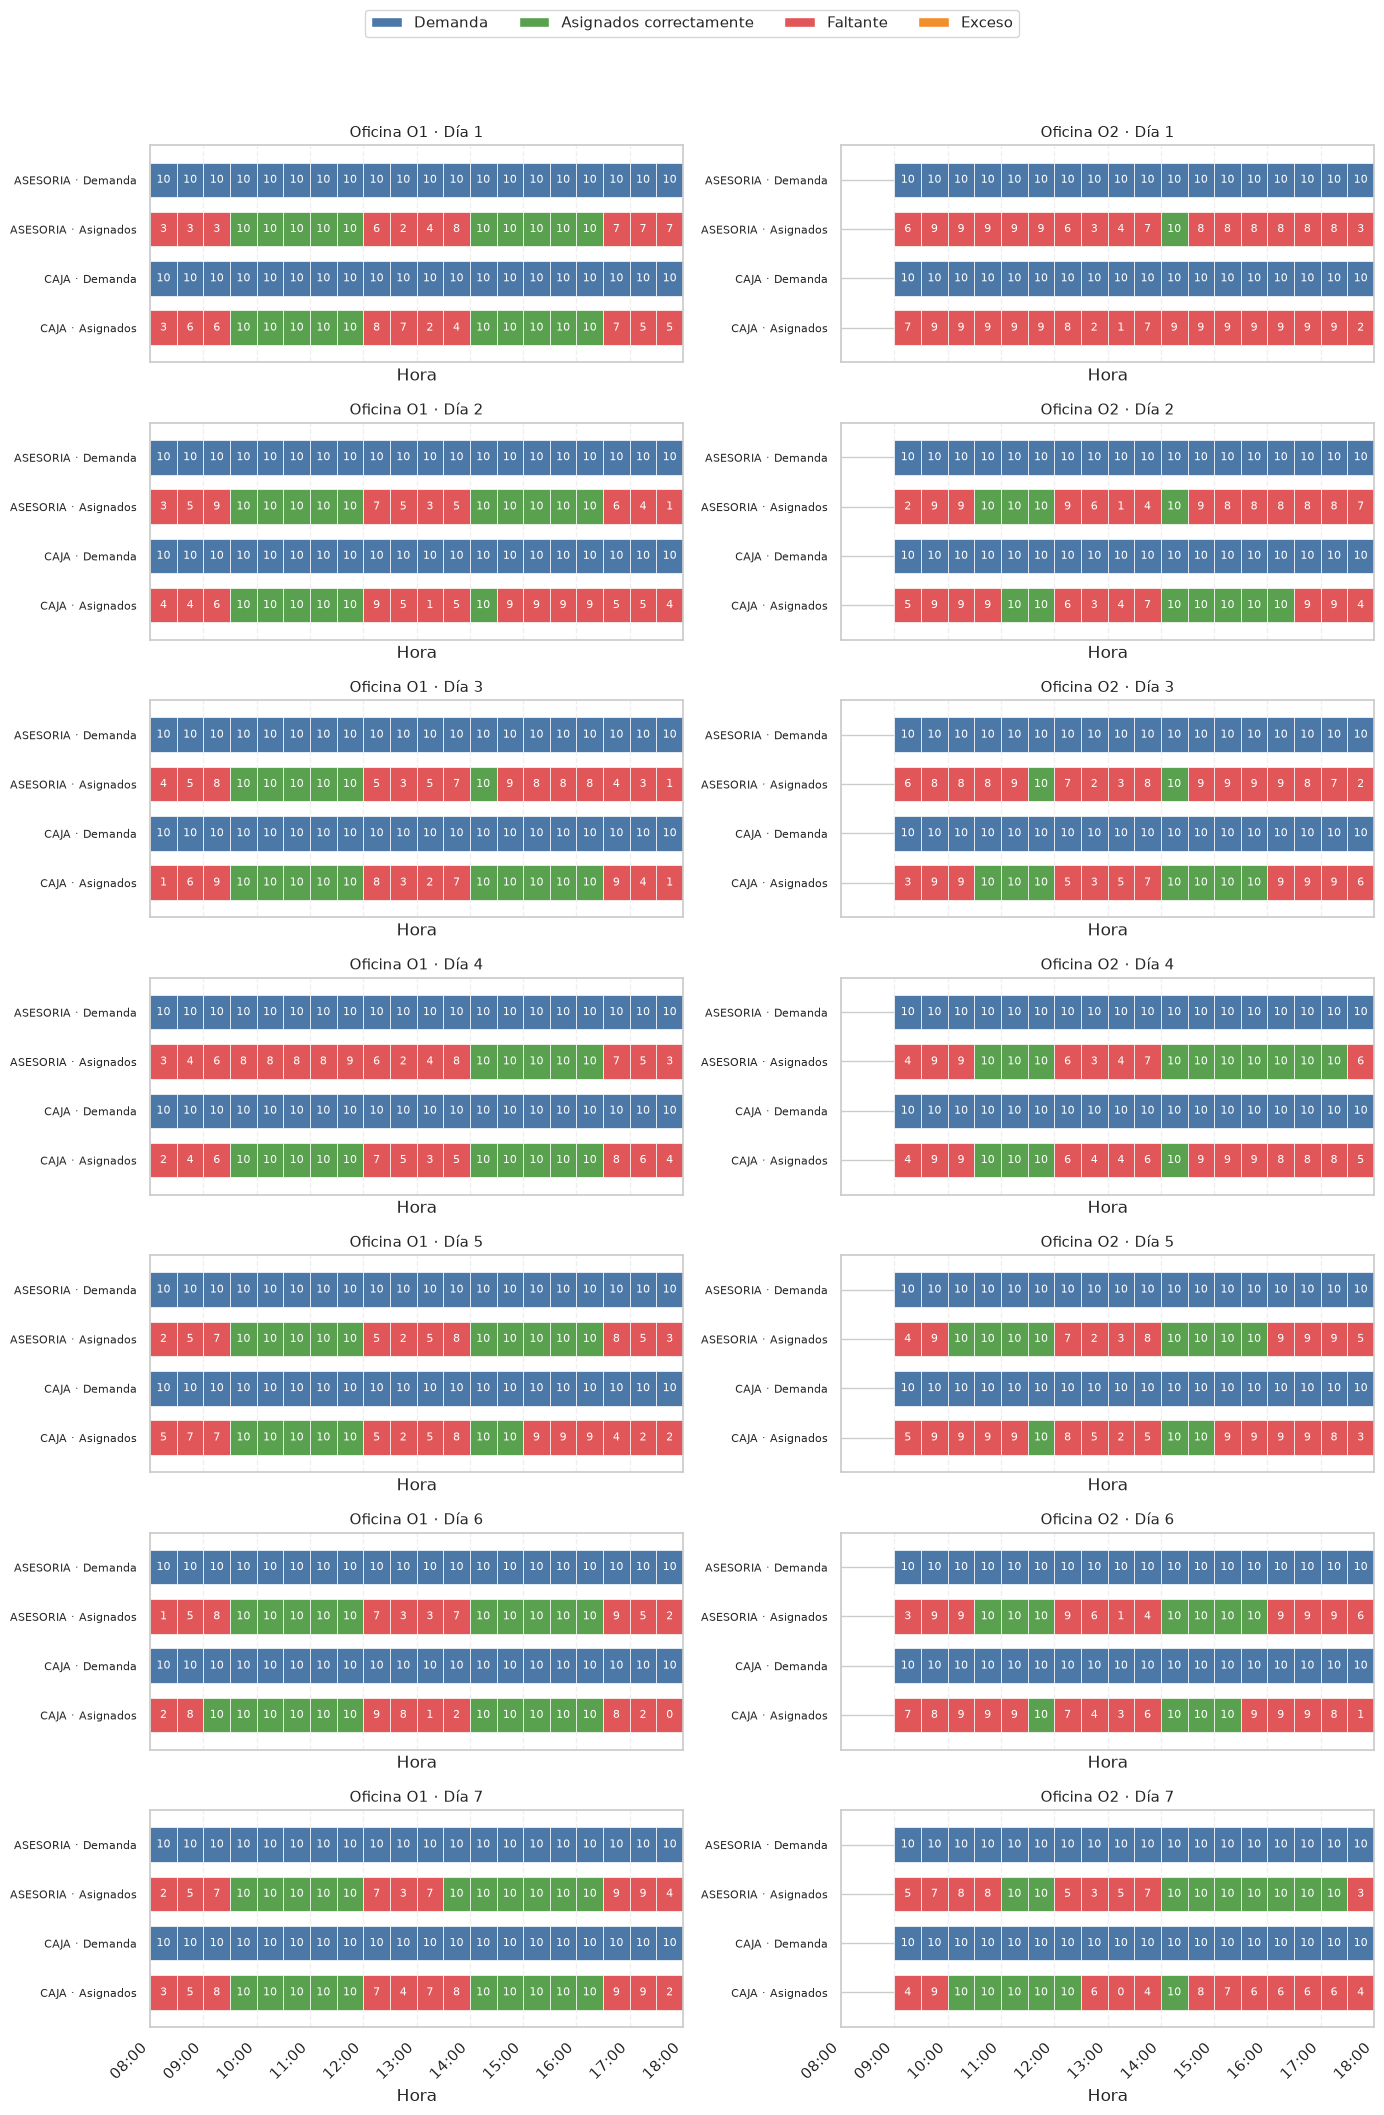

In [96]:
df=pd.DataFrame(coverage)
graficar_demanda_asignaciones(
    df,
    duracion_slot=30,
    hora_inicio=datetime.strptime("08:00", "%H:%M").time(),
    hora_fin=datetime.strptime("18:00", "%H:%M").time(),
)

In [86]:
write_csv("schedule.csv", schedule)
write_csv("coverage.csv", coverage)
write_csv("employee_hours.csv", employee_hours)

Archivo generado: /home/daniel/Documents/workforce/schedule.csv
Archivo generado: /home/daniel/Documents/workforce/coverage.csv
Archivo generado: /home/daniel/Documents/workforce/employee_hours.csv
